In [1]:
import numpy
import pandas as pd
import pysam
import plotly.express as px
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import seaborn as sns
import os
import json

In [2]:
def get_vcf_record_somatic(input_vcf, GT=True, somatic = False, heteroplasmic = False, tier = "HighConf"):
    vcf_input = pysam.VariantFile(input_vcf, "r")
    vcf_record = []

    for record in vcf_input:
        pos = record.pos
        ref = record.ref
        alt = record.alts[0]
        # vcf_record.append(pos)
        vcf_record.append("m.%d.%s>%s" %(pos, ref, alt))


    samples = [str(s) for s in vcf_input.header.samples if ":" not in s]
    sample_size = len(samples)
    sample_dict = dict(zip(samples, range(sample_size)))
    record_count = len(vcf_record)
    record_dict = dict(zip(vcf_record, range(record_count)))


    vcf_input = pysam.VariantFile(input_vcf, "r")
    matrix = numpy.zeros([record_count, sample_size])


    for record in vcf_input:
        for ind, alt in enumerate(record.alts):
            record_index = record_dict["m.%d.%s>%s" %(record.pos, record.ref, alt)]
            for sample in samples:
                sample_index = [sample_dict[sample]]
                hf_value = record.samples[str(sample)]["AF"][ind]
                GT_value = record.samples[str(sample)]["GT"][ind]
                if record.samples[str(sample)]["Tier"][ind] != tier:
                    continue
                if heteroplasmic:
                    if record.samples[str(sample)]["HeteroplasmyStatus"][0] != "hetero":
                        continue
                if somatic:
                    if record.samples[str(sample)]["VariantOrigin"][0] != "somatic":
                        continue
                if pd.isna(hf_value):
                    continue
                if GT:
                    matrix[record_index, sample_index] = int(GT_value)
                else:
                    matrix[record_index, sample_index] = float(hf_value)

    df = pd.DataFrame(matrix, columns = samples, index = vcf_record)
    return df



In [3]:
# code dict
df_manifest = pd.read_csv("/Users/suhang/Analysis/SMaHT_sample/smaht_manifest_2026-06-17-18h-45m.tsv", sep = "\t", header = 2)
code_dict = {}
for item in df_manifest['SampleTissues']:
    key, value = item.replace(" ", "").split("-")
    code_dict[key] = value
#code_dict = dict(zip(["-".join(i.split("-")[:2]) for i in df_manifest['SampleName'].tolist() if not pd.isna(i)],df_manifest['SampleTissues'].tolist()))

code_dict

{'3S': 'Heart',
 '3G': 'Colon,Desc',
 '3A': 'WholeBlood',
 '3AK': 'Brain,FrontalLobe',
 '3C': 'Esophagus',
 '3M': 'AdrenalGland,R',
 '3AH': 'Muscle',
 '3O': 'Aorta',
 '3I': 'Liver',
 '3U': 'Testis,L',
 '3AL': 'Brain,TemporalLobe',
 '3AF': 'Skin,Abdomen',
 '3Q': 'Lung',
 '3E': 'Colon,Asc',
 '3K': 'AdrenalGland,L',
 '3AN': 'Brain,Hippocampus,L',
 '3AD': 'Skin,Calf',
 '3AC': 'Fibroblast',
 '3AO': 'Brain,Hippocampus,R',
 '3AM': 'Brain,Cerebellum',
 '3B': 'BuccalSwab',
 '3Y': 'Ovary,L'}

In [11]:
input_vcf = "/Users/suhang/Analysis/SMaHT_sample/P25/test/p25.filled.vcf.gz"
# input_vcf = "/Users/suhang/Analysis/SMaHT_sample/P25/p25_merge_1/p25_merged.vcf.gz"
df_het = get_vcf_record_somatic(input_vcf, GT=False, somatic=False, heteroplasmic=True)
print(df_het.columns)
# include the top 8 tissues with the most variants
# col = (df_het>0.01).sum().sort_values(ascending=False).head(6).index.tolist() + ["SMHT005-3AC", "SMHT005-3Q"]
# df_het = df_het[col]
# (df_het>0.01).sum()
[c.split("-")[1] for c in col]


Index(['SMHT001-3A', 'SMHT001-3AC', 'SMHT001-3AD', 'SMHT001-3AF',
       'SMHT001-3AH', 'SMHT001-3AK', 'SMHT001-3AL', 'SMHT001-3AM',
       'SMHT001-3AN', 'SMHT001-3AO',
       ...
       'SMHT043-3AN', 'SMHT043-3B', 'SMHT043-3C', 'SMHT043-3E', 'SMHT043-3G',
       'SMHT043-3I', 'SMHT043-3K', 'SMHT043-3O', 'SMHT043-3Q', 'SMHT043-3U'],
      dtype='str', length=395)


['3B', '3AC', '3Q']

df_het["SMHT005-3AC"]

In [12]:
col = [c for c in df_het.columns if c.startswith("SMHT005")]
df_het.loc['m.7056.G>A',col]

SMHT005-3A     0.0000
SMHT005-3AC    0.0126
SMHT005-3AD    0.0215
SMHT005-3AF    0.0152
SMHT005-3AH    0.0100
SMHT005-3AK    0.0132
SMHT005-3AL    0.0174
SMHT005-3AM    0.0148
SMHT005-3AN    0.0177
SMHT005-3AO    0.0220
SMHT005-3B     0.0130
SMHT005-3C     0.0087
SMHT005-3E     0.0111
SMHT005-3G     0.0115
SMHT005-3I     0.0079
SMHT005-3M     0.0471
SMHT005-3O     0.0000
SMHT005-3Q     0.0125
SMHT005-3S     0.0000
SMHT005-3U     0.0129
Name: m.7056.G>A, dtype: float64

In [21]:
# Figure size (cm): wide/tall enough for circos + rotated bar labels
fig_w_cm, fig_h_cm = 5, 5
fig_w_in = fig_w_cm / 2.54
fig_h_in = fig_h_cm / 2.54
# inch

In [22]:
# 2079*4 * 

['AdrenalGland,L', 'Brain,FrontalLobe', 'Brain,TemporalLobe', 'Fibroblast', 'Lung', 'Muscle', 'Testis,L']
{'3A': '#FF382E', '3B': '#75001F', '3C': '#FFB161', '3E': '#C0B5E7', '3G': '#9D4BBF', '3I': '#FF4AA9', '3K': '#EA7A00', '3M': '#EA7A00', '3O': '#F99B9B', '3Q': '#1DDD30', '3S': '#DDD824', '3U': '#AAF8B4', '3W': '#AAF8B4', '3Y': '#FFAFD4', '3AA': '#FFAFD4', '3AC': '#FFE98D', '3AD': '#0EC1B8', '3AF': '#91E5DB', '3AH': '#AA9A41', '3AK': '#BBE7FF', '3AL': '#76AEFF', '3AM': '#1655C4', '3AN': '#002A66', '3AO': '#002A66'}
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0
0.0035000001080334187
0.0
0.0
0.0
0.0
0.0
0.0
0.013899999670684338
0.0
0.003599999938160181
0.0
0.0
0.0
0.0
0.0
0.0
m.72.T>C    0.0000
m.72.T>C    0.0057
Name: SMHT012-3K, dtype: float64


ValueError: The truth value of a Series is ambiguous. Use a.empty, a.bool(), a.item(), a.any() or a.all().

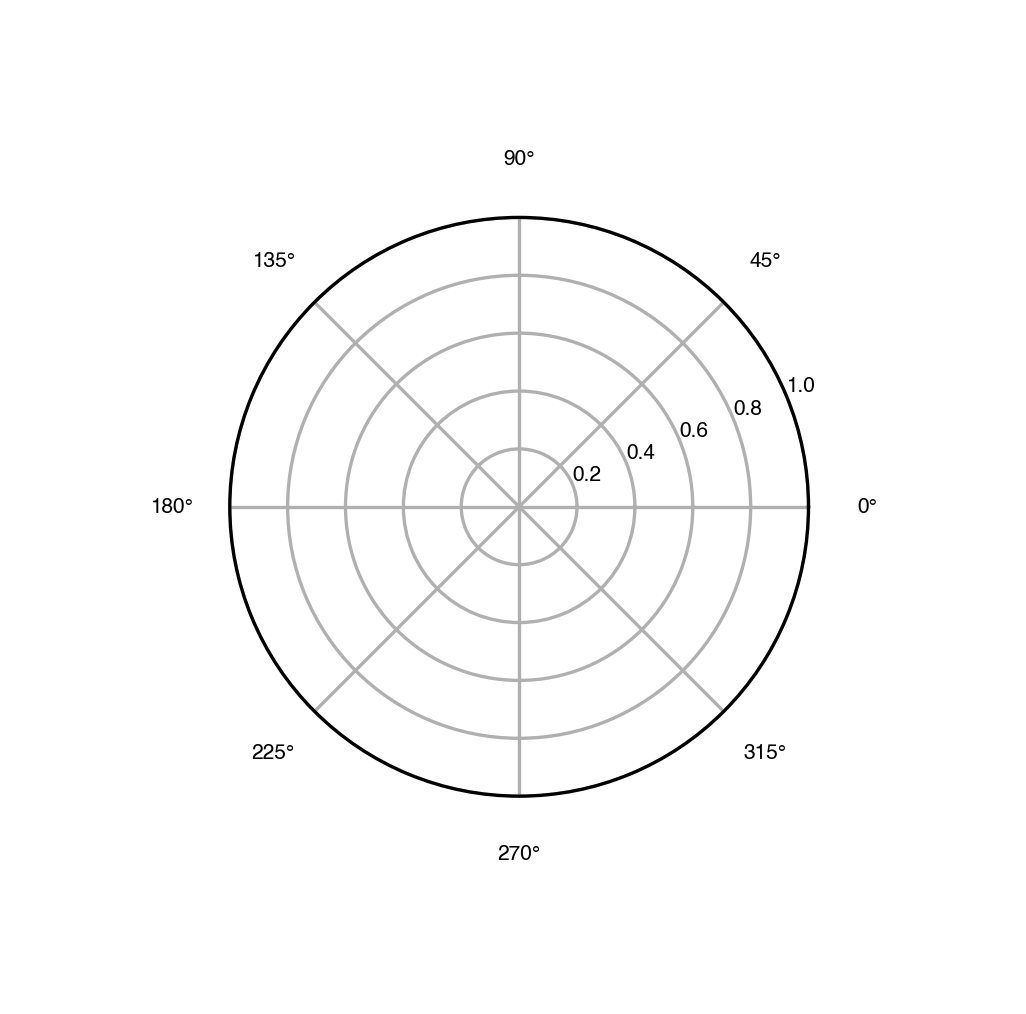

In [26]:
# SNP, Indel, Haplotype Distribution
from pycirclize import Circos
from pycirclize.parser import Gff
from pycirclize.utils import load_eukaryote_example_dataset
import re
from pycirclize.utils import load_example_tree_file, ColorCycler
from pycirclize import config as pycirc_config
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib import gridspec
from matplotlib.text import Text
from scipy.stats import gaussian_kde
import numpy

# --------------------- change here to adjust the subplot and layout ---------------------
sample_set = "SMHT005"
fig= plt.figure(figsize=(fig_w_in, fig_h_in), dpi=300)
# fig, ax1 = plt.subplots(figsize=(fig_w_in, fig_h_in), dpi=300)
gs = gridspec.GridSpec(
    nrows=1,
    ncols=1,
    figure=fig,
    # height_ratios=[15, 1],
    hspace=0.01,
    top=0.99,
    bottom=0.01,
    left=0.01,
    right=0.99,
)
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = 'Helvetica'
plt.rcParams['font.size'] = 5        # Global default base size
# --------------------- ------------------------------------------------- ---------------------

ax1 = fig.add_subplot(gs[0, 0], polar=True)
# ax2 = fig.add_subplot(gs[1, 0])

def _clip_circos_to_axes(ax):
    """Keep pycirclize drawing inside the polar subplot (grid 0)."""
    ax.set_ylim(0, pycirc_config.MAX_R)
    clip_patch = ax.patch
    for artist in ax.get_children():
        if isinstance(artist, Text):
            artist.set_clip_on(False)
            continue
        if hasattr(artist, "set_clip_on"):
            artist.set_clip_on(True)
        if hasattr(artist, "set_clip_path"):
            artist.set_clip_path(clip_patch)
    for coll in ax.collections:
        coll.set_clip_on(True)
        coll.set_clip_path(clip_patch)

# Keep gene labels from pushing far outside the outer track
pycirc_config.ann_adjust.dr = 0.05

chrM_length = 16569
sector_dict = {"NC_012920.1": chrM_length}
circos = Circos(sector_dict)
chrM_sector = circos.sectors[0]

fontsize = 4
annotation_file = "/Users/suhang/Analysis/SMaHT_sample/SMHT001/summary/combined_per_tissue_vcfs_0416/rCRS.gff3"
gff = Gff(annotation_file)
startpos = 80  # outer track top <= ~92 so labels fit inside r=100
seqid2features = gff.get_seqid2features(feature_type="gene")
for sector in circos.sectors:
    cds_track = sector.add_track((startpos + 5, startpos + 10))
    cds_track.axis(fc="#EEEEEE", ec="none")
    features = seqid2features[sector.name]
    for feature in features:
        if feature.location.strand == 1:
            cds_track.genomic_features(feature, plotstyle="arrow",
                r_lim=(startpos + 7.5, startpos + 10), fc="salmon")
        else:
            cds_track.genomic_features(feature, plotstyle="arrow",
                r_lim=(startpos + 5, startpos + 7.5), fc="skyblue")
        start, end = int(feature.location.start), int(feature.location.end)
        label = feature.qualifiers.get("Name", [""])[0]
        if label == "" or label.startswith("hypothetical"):
            continue
        if feature.qualifiers.get('gene_biotype', [""])[0] == "tRNA":
            continue
        cds_track.annotate((start + end) / 2, label, label_size=fontsize)

for feature in gff.extract_features("D_loop"):
    cds_track.genomic_features(feature, plotstyle="arrow",
        r_lim=(startpos + 5.0, startpos + 7.5), fc="gold", ec="grey", lw=0.5)
    cds_track.annotate((feature.location.start + feature.location.end) / 2,
        "D-loop", label_size=fontsize)

# ---------- data prep ----------
n_bins = 100
bin_edges = numpy.linspace(0, chrM_length, n_bins + 1)
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
tissues = sorted(set([code_dict[col.split("-")[1]] for col in df_het.columns.tolist()]))
n_tissues = len(tissues)
print(tissues)

# occ_mat = numpy.zeros((n_tissues, n_bins))   # variant count per bin
# af_mat  = numpy.zeros((n_tissues, n_bins))   # summed AF per bin

# for i, tid in enumerate(tissues):
#     samplelist = [col for col in df_het.columns if code_dict[col.split("-")[1]] == tid]
#     for record in df_het.index:
#         for tid in samplelist:
#             val = df_het.loc[record, tid]
#             if val < 0.01:
#                 continue
#             pos = int(re.findall(r'\d+', record)[0])
#             b = min(numpy.digitize(pos, bin_edges) - 1, n_bins - 1)
#             occ_mat[i, b] += 1
#             af_mat[i, b] += val

# # normalize occurrence row-wise so each tissue is on [0, 1]
# occ_norm = occ_mat / (occ_mat.max(axis=1, keepdims=True) + 1e-9)
# # mean AF per bin (0 where no variant)
# af_avg = numpy.where(occ_mat > 0, af_mat / (occ_mat + 1e-9), 0)

# # ---------- track 1: occurrence density heatmap (tissues × genomic bins) ----------
# hm_occ = chrM_sector.add_track((startpos - 22, startpos - 2))
# hm_occ.heatmap(occ_norm,  vmin=0, vmax=1, cmap="viridis")
ColorCycler.set_cmap("tab20")
# group_name2color = {code_dict[col.split("-")[1]]: ColorCycler() for col in df_het.columns}
smaht_dict = json.load(open("/Users/suhang/Analysis/SMaHT_sample/SMaHT_Mitogenome/scripts/smaht_tissue_colors_FINAL.json"))
def _hex_color(h):
    h = str(h).strip()
    return h if h.startswith("#") else f"#{h}"
group_name2color = {k: _hex_color(v["tissue_color_hex"]) for k, v in smaht_dict.items()}
print(group_name2color)
# ---------- track 2: mean AF heatmap ----------
# hm_af = chrM_sector.add_track((startpos - 24, startpos - 2))
# # hm_occ.heatmap(occ_norm,  vmin=0, vmax=1, cmap="viridis")
# hm_af.heatmap(af_avg, vmin=0, vmax=max(af_avg.flatten()), cmap="Blues")
# df_sub = df_het.copy()
# hm_af.axis(fc="white",ec="black", lw=0.5, alpha = 0.1)
# for tid in df_sub.columns:
#     pos_list = []
#     var_list = []
#     for record in df_sub.index:
#         if df_sub.loc[record, tid] <0.01:
#             continue
#         pos = int(re.findall(r'\d+', record)[0])
#         pos_list.append(pos)
#         var_list.append(df_sub.loc[record, tid])
    #hm_af.scatter(pos_list, var_list, color = group_name2color[code_dict[tid.split("-")[1]]], s = 20)
    # pos_track.bar(x[1:], y, label = code_dict[col.split("-")[1]], width = 50)
    # y_ticks = list(range(0, max(y), 100))

# hm_af.heatmap(af_avg, vmin=0, vmax=1, cmap="Blues")

# ---------- track 3: per-tissue KDE fill_between ----------
spos = startpos - 2
width_t = max(1.5, (spos - 5) / n_tissues)
x_eval = numpy.linspace(0, chrM_length, 2000)
kde_top = spos
for tid in tissues:
    pos_list = []
    samplelist = [col for col in df_het.columns if code_dict[col.split("-")[1]] == tid]
    for record in df_het.index:
        for tid in samplelist:
            val = df_het.loc[record, tid]
            print(val)
            if val < 0.001 or pd.isna(val):
                continue
            pos = int(re.findall(r'\d+', record)[0])
            pos_list.append(pos)
    
    color = group_name2color[tid.split("-")[1]]
    t = chrM_sector.add_track((spos - width_t, spos))
    t.axis(fc="white", ec="none", lw=0)
    if len(pos_list) >= 2:
        kde = gaussian_kde(pos_list, bw_method=0.01)
        density = kde(x_eval)
        if density.max() == 0:
            continue
        density /= (density.max())
        t.fill_between(x_eval, density, color=color, alpha=0.8,
                       label=code_dict[tid.split("-")[1]])
    elif len(pos_list) == 1:
        t.bar(pos_list, [0.5], color=color, width = 10,
                  label=code_dict[tid.split("-")[1]])
    spos -= width_t
kde_bottom = spos

circos.plotfig(ax=ax1)
_clip_circos_to_axes(ax1)
ax1.set_aspect("equal", adjustable="box", anchor="C")
ax1.margins(0)
# fig.suptitle(
#     "%s Heteroplasmic Variant Distribution (High Confidence)" % sample_set,
#     fontsize=8,
#     y=0.985,
# )
# ax1.legend(bbox_to_anchor=(1.1, 1), fontsize=8, loc='upper left',
#            borderaxespad=0., facecolor='white')




varnum = {}
for tid in tissues:
    varnum[tid] = 0
    total = 0
    for col in df_het.columns:
        if code_dict[col.split("-")[1]] == tid:
            df_sub = df_het[col]
            df_sub = df_sub[df_sub > 0.01]
            varnum[tid] += df_sub.shape[0]
            total += 1
    varnum[tid] = varnum[tid] / total if total > 0 else 0
sorted_varnum = sorted(varnum.items(), key=lambda x: x[1], reverse=True)

# sns.barplot(
#     x=[i[0] for i in sorted_varnum],
#     y=[i[1] for i in sorted_varnum],
#     ax=ax2,
#     linewidth=0.3,
#     edgecolor="black",
# )
# for patch in ax2.patches:
#     patch.set_linewidth(0.3)
# ax2.tick_params(axis="both", width=0.4, length=2)
# for spine in ax2.spines.values():
#     spine.set_linewidth(0.4)
# ax2.set_xticklabels(ax2.get_xticklabels(), rotation=90, ha="right", fontsize=4)
# for label in ax2.get_xticklabels():
#     label.set_clip_on(False)
# # ax2.tick_params(axis="x", pad=0.5)
# ax2.tick_params(axis="y", labelsize=5)

plt.savefig(
    "p25_mt_var_distribution.svg",
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.01,
)


# Heatmaps

In [ ]:
df_het_ = df_het[df_het > 0.01].fillna(0)
df_het_[df_het_ > 0] = 1
df_het_

In [ ]:
def plot_het_distribution(df_het, code_dict, ax, title):
    het_info = {}
    for index, row in df_het.iterrows():
        pos = int(index.split(".")[1])
        for col in df_het.columns:
            if col == "pos":
                continue
            if row[col] > 0.01:
                tid = col.split("-")[1]
                het_info[tid] = het_info.get(tid, [])  + [pos]
    
    for tid, pos_list in het_info.items():
        sns.histplot(pos_list, label=code_dict[tid], ax = ax, kde=True, bins=20)
    plt.ylabel("")

In [ ]:
def plot_het_burden(df_het, code_dict, ax, title, label):
    het_info = {}
    for index, row in df_het.iterrows():
        pos = int(index.split(".")[1])
        for col in df_het.columns:
            if col == "pos":
                continue
            if row[col] > 0.01:
                tid = col.split("-")[1]
                het_info[tid] = het_info.get(tid, 0)  + 1
    
    pos_list = [het_info.get(tid, 0) for tid in label]
    sns.barplot(pos_list, label= label, ax = ax)
    ax.set_ylabel(title)
    ax.set_yticks([])

In [ ]:
fig, ax = plt.subplots(len(features) + 1, 1, figsize=(20, 20))
axes = ax.flatten()
burden = []
df_het["pos"] = df_het.index.str.split(".").str[1].astype(int)
tissue_list = sorted(set([col.split("-")[1] for col in df_het.columns.tolist() if col != "pos"]))

for i, feature in enumerate(features):
    genename = feature.id.replace("gene-", "")
    spos, epos = feature.location.start, feature.location.end
    df_sub = df_het[(df_het["pos"] >= spos) & (df_het["pos"] <= epos)]
    plot_het_burden(df_sub, code_dict, axes[i], genename, tissue_list)
for feature in gff.extract_features("D_loop"):
    spos, epos = feature.location.start, feature.location.end
    df_sub = df_het[(df_het["pos"] >= spos) & (df_het["pos"] <= epos)]
    plot_het_burden(df_sub, code_dict, axes[i+1], "D-loop", tissue_list)

axes[-1].set_xticklabels(tissue_list, rotation=45)

In [ ]:
burden.sort(key=lambda x: x[1], reverse=True)

In [ ]:
fig, ax = plt.subplots(6,7, figsize=(20, 20))
axes = ax.flatten()

df_het["pos"] = df_het.index.str.split(".").str[1].astype(int)

for t, tid in enumerate(tissues):
    samplelist = [col for col in df_het.columns[:-1] if code_dict[col.split("-")[1]] == tid] + ["pos"]
    df_tissue = df_het[samplelist]
    
    burden = []
    for i, feature in enumerate(features):
        genename = feature.id.replace("gene-", "")
        spos, epos = feature.location.start, feature.location.end
        df_sub = df_tissue[(df_tissue["pos"].astype(int) >= spos) & (df_tissue["pos"].astype(int) <= epos)]
        
        burden.append([genename,df_sub.shape[0]/(epos - spos)])
    burden.sort(key=lambda x: x[1], reverse=True)      
    print(burden)

    burden = numpy.array(burden)
    ax = sns.barplot(x=burden[:, 0], y=burden[:, 1].astype(float), ax=axes[t])
    ax.set_xlabel("Genes")
    ax.set_ylabel("Heteroplasmy Burden")
    plt.xticks(rotation=90)

In [ ]:
df_het